# Chapitre 18 - Exercices 18.16 à 18.20 : tests multiples

Ces cinq exercices portent sur la section 18.7 du livre (évaluation de l'importance de
chaque variable et problème des **tests multiples**) :

- **18.16** : la méthode de Bonferroni contrôle le taux d'erreur par famille (FWER) ;
- **18.17** : équivalence entre la procédure de Benjamini–Hochberg et l'estimation
  « plug-in » du taux de fausses découvertes (FDR) ;
- **18.18** : expression bayésienne du pFDR à l'aide de l'erreur de type I et de la
  puissance ;
- **18.19** : étude complète (FDR plug-in, BH, estimation de $\pi_0$) sur des données de
  micro-puces ;
- **18.20** : démonstration du résultat (18.53), $\text{pFDR}(\Gamma) = \Pr(Z = 0 \mid t \in \Gamma)$.

Les fonctions utilisées sont dans `esl/ch18_grande_dimension_complements.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch18_grande_dimension_complements as g18
set_style()

### Rappels communs : vocabulaire des tests multiples

On teste $M$ hypothèses nulles $H_{01}, \dots, H_{0M}$ (par exemple « le gène $j$ a la
même expression moyenne dans les deux groupes »). Chaque test fournit une **p-valeur**
$p_j$. Sous $H_{0j}$, $p_j$ suit (au moins approximativement) la loi uniforme sur
$[0, 1]$, de sorte que $\Pr(p_j < u) = u$ : rejeter quand $p_j < u$ donne une erreur de
type I égale à $u$.

Le tableau 18.5 du livre résume les issues possibles :

| | non rejetée | rejetée | total |
|---|---|---|---|
| $H_0$ vraie | $U$ | $V$ | $M_0$ |
| $H_0$ fausse | $T$ | $S$ | $M_1$ |
| total | $M - R$ | $R$ | $M$ |

$V$ est le nombre de **faux positifs** et $R$ le nombre total de rejets.

- **FWER** (taux d'erreur par famille) : $\Pr(V \ge 1)$.
- **FDR** (taux de fausses découvertes, éq. (18.43)) : $E(V/R)$, avec la convention
  $V/R = 0$ si $R = 0$.
- **pFDR** (FDR positif, éq. (18.50)) : $E(V/R \mid R > 0)$.

## Exercice 18.16 : Méthode de Bonferroni

**Énoncé (reformulé).** On teste $M$ hypothèses nulles $H_{0j}$ de p-valeurs $p_j$. Soit
$A$ l'événement « au moins une hypothèse nulle est rejetée à tort » et $A_j$ l'événement
« la $j$-ème hypothèse nulle est rejetée à tort ». La méthode de Bonferroni rejette
$H_{0j}$ si $p_j < \alpha/M$.

(a) Montrer que $\Pr(A) \le \alpha$. *Indication :*
$\Pr(A_j \cup A_{j'}) = \Pr(A_j) + \Pr(A_{j'}) - \Pr(A_j \cap A_{j'})$.

(b) Si les hypothèses sont indépendantes,
$\Pr(A) = 1 - \Pr(A^c) = 1 - \prod_j \Pr(A_j^c) = 1 - (1 - \alpha/M)^M$. En déduire que
$\Pr(A) \approx \alpha$ dans ce cas.

### (a) Inégalité de la réunion

**Étape 1 : deux événements.** D'après l'indication, et puisqu'une probabilité est
positive,
$\Pr(A_j \cup A_{j'}) = \Pr(A_j) + \Pr(A_{j'}) - \Pr(A_j \cap A_{j'}) \le \Pr(A_j) + \Pr(A_{j'})$.

**Étape 2 : récurrence.** Supposons $\Pr\big(\bigcup_{j=1}^{m} A_j\big) \le \sum_{j=1}^m \Pr(A_j)$.
En appliquant l'étape 1 aux deux événements $B = \bigcup_{j=1}^{m} A_j$ et $A_{m+1}$ :

$$
\Pr\Big(\bigcup_{j=1}^{m+1} A_j\Big) \le \Pr(B) + \Pr(A_{m+1}) \le \sum_{j=1}^{m+1} \Pr(A_j).
$$

C'est l'**inégalité de Boole** : $\Pr\big(\bigcup_j A_j\big) \le \sum_j \Pr(A_j)$.

**Étape 3 : probabilité de chaque fausse alarme.** Si $H_{0j}$ est fausse, l'événement
$A_j$ est impossible (on ne peut pas la rejeter *à tort*) : $\Pr(A_j) = 0$. Si $H_{0j}$ est
vraie, $p_j$ est uniforme et $\Pr(A_j) = \Pr(p_j < \alpha/M) = \alpha/M$.

**Conclusion.** Avec $M_0 \le M$ hypothèses nulles vraies,

$$
\Pr(A) = \Pr\Big(\bigcup_{j=1}^M A_j\Big) \le \sum_{j=1}^M \Pr(A_j) = M_0\,\frac{\alpha}{M} \le \alpha .
$$

Aucune hypothèse d'indépendance n'a été utilisée : la garantie est valable quelle que
soit la dépendance entre les tests.

### (b) Cas indépendant : la borne est presque atteinte

On suppose ici toutes les hypothèses nulles vraies et les tests indépendants, de sorte
que $\Pr(A) = 1 - (1 - \alpha/M)^M$. Encadrons cette quantité.

- **Majoration** (inégalité de Bernoulli $(1 - x)^M \ge 1 - Mx$ pour $0 \le x \le 1$) :
  $(1 - \alpha/M)^M \ge 1 - \alpha$, donc $\Pr(A) \le \alpha$ (on retrouve (a)).
- **Minoration** : $\log(1 - x) \le -x$ (concavité du logarithme), donc
  $(1 - \alpha/M)^M = e^{M\log(1 - \alpha/M)} \le e^{-\alpha}$, et
  $\Pr(A) \ge 1 - e^{-\alpha}$.
- Enfin $e^{-\alpha} \le 1 - \alpha + \alpha^2/2$ pour $\alpha \ge 0$ : la fonction
  $g(\alpha) = e^{-\alpha} - 1 + \alpha - \alpha^2/2$ vérifie $g(0) = 0$ et
  $g'(\alpha) = 1 - \alpha - e^{-\alpha} \le 0$ (car $e^{-\alpha} \ge 1 - \alpha$, inégalité de
  convexité), donc $g \le 0$ sur $[0, +\infty[$.

On obtient l'encadrement, valable pour tout $M$ :

$$
\alpha - \frac{\alpha^2}{2} \;\le\; 1 - e^{-\alpha} \;\le\; \Pr(A) \;\le\; \alpha .
$$

L'erreur relative est au plus $\alpha/2$ : pour $\alpha = 0{,}05$,
$0{,}0488 \le \Pr(A) \le 0{,}05$. Donc $\Pr(A) \approx \alpha$. De plus
$(1 - \alpha/M)^M \to e^{-\alpha}$ quand $M \to \infty$.

In [2]:
alpha = 0.05
Ms = np.unique(np.logspace(0, 4, 50).astype(int))
fwer_exact = 1 - (1 - alpha / Ms) ** Ms
print("M = 1 : %.4f   M = 10 : %.4f   M = 10000 : %.4f   1 - exp(-alpha) = %.4f"
      % (fwer_exact[0], 1 - (1 - alpha / 10) ** 10, fwer_exact[-1], 1 - np.exp(-alpha)))

M = 1 : 0.0500   M = 10 : 0.0489   M = 10000 : 0.0488   1 - exp(-alpha) = 0.0488


### Simulation : tests indépendants ou corrélés

On simule $M$ statistiques $z_j$ gaussiennes sous $H_0$, de corrélation commune $\rho$
($z_j = \sqrt\rho\,W + \sqrt{1 - \rho}\,E_j$), et des tests bilatéraux. On estime le
FWER de Bonferroni sur 4000 répétitions.

In [3]:
rng = np.random.RandomState(0)
n_rep = 4000
res = {}
for rho in [0.0, 0.5, 0.9]:
    fw = []
    for M in [1, 10, 100, 1000]:
        z = np.sqrt(rho) * rng.randn(n_rep, 1) + np.sqrt(1 - rho) * rng.randn(n_rep, M)
        pv = 2 * stats.norm.sf(np.abs(z))
        fw.append(np.mean(np.any(pv < alpha / M, axis=1)))
    res[rho] = fw
    print("rho = %.1f :" % rho, np.round(fw, 4))

rho = 0.0 : [0.051  0.052  0.0442 0.041 ]


rho = 0.5 : [0.0498 0.0422 0.0332 0.022 ]


rho = 0.9 : [0.052  0.0165 0.0068 0.0012]


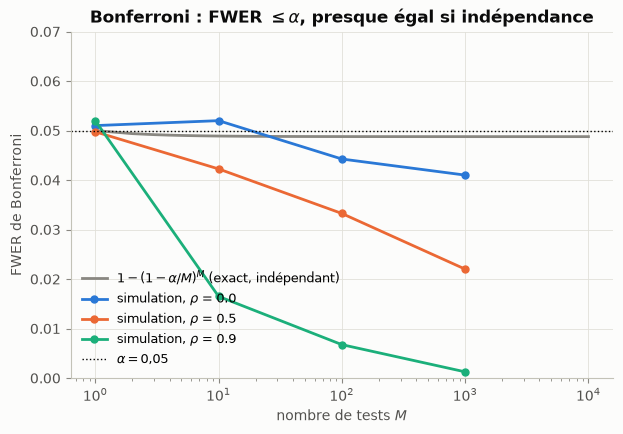

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(Ms, fwer_exact, color=GRAY, label=r"$1-(1-\alpha/M)^M$ (exact, indépendant)")
for c, rho in zip(COLORS, [0.0, 0.5, 0.9]):
    ax.semilogx([1, 10, 100, 1000], res[rho], "o-", color=c,
                label=r"simulation, $\rho$ = %.1f" % rho)
ax.axhline(alpha, color="k", lw=1, ls=":", label=r"$\alpha = 0{,}05$")
ax.set_xlabel("nombre de tests $M$")
ax.set_ylabel("FWER de Bonferroni")
ax.set_ylim(0, 0.07)
ax.set_title("Bonferroni : FWER $\\leq \\alpha$, presque égal si indépendance")
ax.legend(loc="lower left")
plt.show()

Sans corrélation, le FWER colle à $\alpha$ ; avec une forte corrélation positive, les
fausses alarmes ont tendance à arriver ensemble, le FWER est bien inférieur à $\alpha$ :
Bonferroni devient **conservatrice** (elle rejette trop peu).

> **À retenir.** Par l'inégalité de Boole, rejeter quand $p_j < \alpha/M$ garantit
> $\text{FWER} \le \alpha$ sans aucune hypothèse de dépendance ; en cas d'indépendance le
> FWER vaut $1 - (1 - \alpha/M)^M \in [1 - e^{-\alpha}, \alpha]$.

## Exercice 18.17 : Benjamini–Hochberg et FDR plug-in sont équivalents

**Énoncé (reformulé).** Avec les notations de l'algorithme 18.2 :

(a) montrer que, pour le seuil de rejet $p_0 = p_{(L)}$, une proportion d'au plus $p_0$
des statistiques permutées $t_{kj}$ dépasse $|T|_{(L)}$, la $L$-ième plus grande valeur
des $|t_j|$. En déduire que l'estimation plug-in $\widehat{\text{FDR}}$ est inférieure
ou égale à $p_0 \cdot M/L = \alpha$ ;

(b) montrer que le seuil $|T|_{(L+1)}$ donne un test dont le FDR estimé est supérieur
à $\alpha$.

### Rappels : les objets en jeu

- **Statistiques observées** $t_j$, $j = 1, \dots, M$ (t-statistiques (18.38)), et
  **statistiques permutées** $t_{kj}$, $k = 1, \dots, K$, recalculées après $K$
  permutations aléatoires des étiquettes de groupe (elles simulent l'hypothèse nulle).
- **p-valeurs mutualisées** (éq. (18.41)) : la proportion de toutes les $MK$ valeurs
  permutées qui dépassent $|t_j|$ :
  $$p_j = \frac{1}{MK}\sum_{j'=1}^M\sum_{k=1}^K I(|t_{kj'}| \ge |t_j|).$$
- **BH (algorithme 18.2)** : on ordonne $p_{(1)} \le \dots \le p_{(M)}$, on pose
  $L = \max\{j : p_{(j)} < \alpha j/M\}$ (éq. (18.44)) et on rejette les $H_{0j}$ telles
  que $p_j \le p_{(L)}$.
- **Plug-in (algorithme 18.3)** : pour un seuil $C$,
  $R_{\text{obs}}(C) = \#\{j : |t_j| \ge C\}$,
  $\widehat{E(V)}(C) = \frac1K\#\{(j, k) : |t_{kj}| \ge C\}$ (nombre moyen de rejets
  par jeu permuté, donc sous $H_0$), et $\widehat{\text{FDR}}(C) = \widehat{E(V)}(C)/R_{\text{obs}}(C)$.

Nous utilisons partout la convention « $\ge$ » (le livre mélange $>$ et $\ge$, ce qui
ne change rien en l'absence d'ex aequo) et supposons les $|t_j|$ deux à deux distincts.

### Lemme : le FDR plug-in au seuil $|T|_{(l)}$

La p-valeur $p_j$ est une fonction **décroissante** de $|t_j|$ : plus la statistique
est grande, moins il y a de valeurs permutées au-dessus. Donc la $l$-ième plus petite
p-valeur correspond à la $l$-ième plus grande statistique : $p_{(l)}$ est la p-valeur du
gène de statistique $|T|_{(l)}$, et

$$
p_{(l)} = \frac{1}{MK}\#\{(j, k) : |t_{kj}| \ge |T|_{(l)}\}
\quad\Longrightarrow\quad
\widehat{E(V)}\big(|T|_{(l)}\big) = \frac1K\#\{(j,k) : |t_{kj}| \ge |T|_{(l)}\} = M\,p_{(l)} .
$$

Par ailleurs exactement $l$ statistiques observées sont $\ge |T|_{(l)}$ :
$R_{\text{obs}}(|T|_{(l)}) = l$. D'où l'identité clé

$$
\widehat{\text{FDR}}\big(|T|_{(l)}\big) = \frac{M\,p_{(l)}}{l}, \qquad l = 1, \dots, M .
$$

### (a) Le seuil de BH a un FDR estimé inférieur à $\alpha$

Pour $l = L$ : la proportion des $MK$ valeurs permutées qui dépassent $|T|_{(L)}$ est
exactement $p_{(L)} = p_0$ (« au plus $p_0$ » avec l'inégalité stricte du livre). Le
lemme donne

$$
\widehat{\text{FDR}}\big(|T|_{(L)}\big) = \frac{M\,p_0}{L} < \frac{M}{L}\cdot\frac{\alpha L}{M} = \alpha ,
$$

où l'on a utilisé la définition de $L$ : $p_{(L)} < \alpha L/M$. (Le livre écrit
$p_0M/L = \alpha$ en assimilant $p_{(L)}$ à la droite $\alpha L/M$ : en réalité on a une
inégalité.) De plus, rejeter les $p_j \le p_{(L)}$ (BH) revient à rejeter les
$|t_j| \ge |T|_{(L)}$ (plug-in au seuil $C = |T|_{(L)}$) : ce sont les mêmes $L$ gènes.

### (b) Un seuil plus bas fait dépasser $\alpha$

Par maximalité de $L$, l'indice $L + 1$ ne vérifie pas la condition (18.44) :
$p_{(L+1)} \ge \alpha(L+1)/M$. Le lemme pour $l = L + 1$ donne

$$
\widehat{\text{FDR}}\big(|T|_{(L+1)}\big) = \frac{M\,p_{(L+1)}}{L + 1} \ge \alpha .
$$

Plus généralement, pour tout $l > L$, $\widehat{\text{FDR}}(|T|_{(l)}) \ge \alpha$. Donc
$|T|_{(L)}$ est **le plus petit seuil observé dont le FDR plug-in est inférieur à
$\alpha$** : la procédure « baisser le seuil tant que $\widehat{\text{FDR}} < \alpha$ »
rejette exactement les mêmes hypothèses que BH.

### Vérification numérique

Sur des données simulées ($M = 2000$ gènes, 20 + 20 échantillons, 100 gènes
réellement différentiels, $K = 200$ permutations), on compare les ensembles rejetés
par BH et par la règle plug-in pour plusieurs $\alpha$, et on vérifie l'identité
$\widehat{\text{FDR}}(|T|_{(l)}) = Mp_{(l)}/l$.

In [5]:
rng = np.random.RandomState(0)
M, n1, n2 = 2000, 20, 20
Xs = rng.randn(M, n1 + n2)
grp = np.r_[np.zeros(n1, bool), np.ones(n2, bool)]
Xs[:100, grp] += 1.2
ts = g18.two_sample_t(Xs, grp)
tps = g18.permutation_t(Xs, grp, 200, rng)
ps = g18.pooled_pvalues(ts, tps)
for a in [0.01, 0.05, 0.1, 0.2]:
    L, rej_bh = g18.benjamini_hochberg(ps, a)
    rej_pi = g18.plugin_reject(ts, tps, a)
    print("alpha = %.2f : L = %3d, rejets plug-in = %3d, ensembles identiques : %s"
          % (a, L, rej_pi.sum(), np.array_equal(rej_bh, rej_pi)))

alpha = 0.01 : L =  29, rejets plug-in =  29, ensembles identiques : True
alpha = 0.05 : L =  51, rejets plug-in =  51, ensembles identiques : True
alpha = 0.10 : L =  71, rejets plug-in =  71, ensembles identiques : True
alpha = 0.20 : L = 107, rejets plug-in = 107, ensembles identiques : True


In [6]:
order_t = np.sort(np.abs(ts))[::-1]
fdr_l, R_l, _ = g18.plugin_fdr(ts, tps, order_t[:300])
l = np.arange(1, 301)
print("écart max entre FDR plug-in et M p_(l) / l : %.2e"
      % np.max(np.abs(fdr_l - M * np.sort(ps)[:300] / l)))

écart max entre FDR plug-in et M p_(l) / l : 1.11e-16


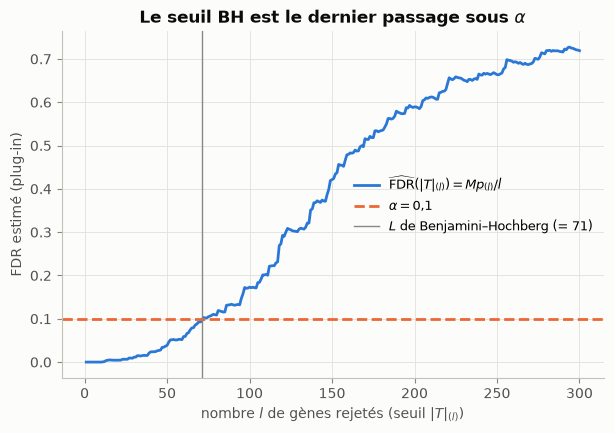

In [7]:
a = 0.1
L, _ = g18.benjamini_hochberg(ps, a)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(l, fdr_l, color=BLUE, label=r"$\widehat{\mathrm{FDR}}(|T|_{(l)}) = M p_{(l)}/l$")
ax.axhline(a, color=ORANGE, ls="--", label=r"$\alpha = 0{,}1$")
ax.axvline(L, color=GRAY, lw=1, label="$L$ de Benjamini–Hochberg (= %d)" % L)
ax.set_xlabel("nombre $l$ de gènes rejetés (seuil $|T|_{(l)}$)")
ax.set_ylabel("FDR estimé (plug-in)")
ax.set_title("Le seuil BH est le dernier passage sous $\\alpha$")
ax.legend()
plt.show()

La courbe n'est pas monotone : BH prend le **dernier** $l$ pour lequel elle est sous
$\alpha$ (et pas le premier passage au-dessus), conformément à la définition de $L$
comme un maximum.

> **À retenir.** Avec les p-valeurs de permutation mutualisées,
> $\widehat{\text{FDR}}(|T|_{(l)}) = Mp_{(l)}/l$ : la condition de BH
> $p_{(l)} < \alpha l/M$ s'écrit $\widehat{\text{FDR}} < \alpha$. BH est donc la règle
> « le seuil le plus bas dont le FDR plug-in reste sous $\alpha$ ».

## Exercice 18.18 : pFDR, erreur de type I et puissance

**Énoncé (reformulé).** À l'aide du résultat (18.53), montrer que

$$
\text{pFDR} = \frac{\pi_0\cdot\{\text{erreur de type I de }\Gamma\}}
{\pi_0\cdot\{\text{erreur de type I de }\Gamma\} + \pi_1\cdot\{\text{puissance de }\Gamma\}}
\qquad\text{(éq. (18.59), Storey 2003).}
$$

### Rappels : le modèle de mélange (18.51)–(18.53)

Chaque test $j$ a une variable cachée $Z_j \in \{0, 1\}$ ($Z_j = 0$ : $H_{0j}$ vraie),
avec $\Pr(Z_j = 0) = \pi_0$ et $\pi_1 = 1 - \pi_0$. La statistique suit $F_0$ si
$Z_j = 0$ et $F_1$ si $Z_j = 1$ ; les couples $(t_j, Z_j)$ sont i.i.d. On rejette quand
$t_j \in \Gamma$ (région de rejet). Le résultat (18.53) affirme
$\text{pFDR}(\Gamma) = \Pr(Z_j = 0 \mid t_j \in \Gamma)$ (démontré à l'exercice 18.20).

Par définition :

- erreur de type I de $\Gamma$ : $\Pr(t_j \in \Gamma \mid Z_j = 0)$ (rejeter à tort) ;
- puissance de $\Gamma$ : $\Pr(t_j \in \Gamma \mid Z_j = 1)$ (rejeter à raison).

### Solution

On applique la **formule de Bayes** à l'événement $\{t_j \in \Gamma\}$, puis la
**formule des probabilités totales** au dénominateur (partition $\{Z_j = 0\}$,
$\{Z_j = 1\}$) :

$$
\begin{aligned}
\text{pFDR}(\Gamma) &= \Pr(Z_j = 0 \mid t_j \in \Gamma)
  = \frac{\Pr(t_j \in \Gamma \mid Z_j = 0)\Pr(Z_j = 0)}{\Pr(t_j \in \Gamma)} \\
&= \frac{\pi_0\Pr(t_j \in \Gamma \mid Z_j = 0)}
   {\pi_0\Pr(t_j \in \Gamma \mid Z_j = 0) + \pi_1\Pr(t_j \in \Gamma \mid Z_j = 1)} \\
&= \frac{\pi_0\cdot\{\text{type I}\}}{\pi_0\cdot\{\text{type I}\} + \pi_1\cdot\{\text{puissance}\}} .
\end{aligned}
$$

> **Intuition.** Parmi les rejets, la part de « fausses découvertes » est la part du
> flux $\pi_0\times$(type I) dans le flux total de rejets. Une région très sévère réduit
> le type I, mais aussi la puissance : le pFDR baisse si le type I diminue plus vite.

### Vérification par simulation

Mélange $\pi_0 = 0{,}8$ de $F_0 = \mathcal N(0, 1)$ et $\pi_1 = 0{,}2$ de
$F_1 = \mathcal N(2{,}5, 1)$, $M = 500$ tests, régions $\Gamma_c = \{|t| > c\}$. On
compare la moyenne de $V/R$ sur les répétitions où $R > 0$ à la formule (18.59).

In [8]:
rng = np.random.RandomState(1)
pi0, mu1, M, n_rep = 0.8, 2.5, 500, 2000
cs = np.linspace(0.5, 4.0, 15)
Zs = rng.rand(n_rep, M) > pi0                          # True = non nulle
tt = rng.randn(n_rep, M) + mu1 * Zs
pfdr_sim = []
for c in cs:
    rej = np.abs(tt) > c
    R = rej.sum(axis=1)
    V = (rej & ~Zs).sum(axis=1)
    pfdr_sim.append(np.mean(V[R > 0] / R[R > 0]))
typeI = 2 * stats.norm.sf(cs)
power = stats.norm.sf(cs - mu1) + stats.norm.cdf(-cs - mu1)
pfdr_th = pi0 * typeI / (pi0 * typeI + (1 - pi0) * power)

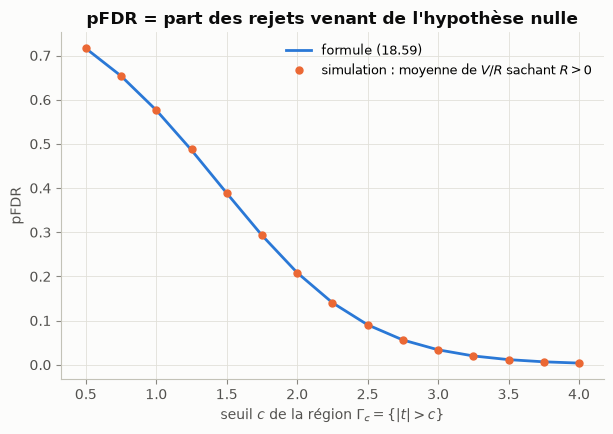

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(cs, pfdr_th, color=BLUE, label="formule (18.59)")
ax.plot(cs, pfdr_sim, "o", color=ORANGE, label=r"simulation : moyenne de $V/R$ sachant $R>0$")
ax.set_xlabel(r"seuil $c$ de la région $\Gamma_c = \{|t| > c\}$")
ax.set_ylabel("pFDR")
ax.set_title("pFDR = part des rejets venant de l'hypothèse nulle")
ax.legend()
plt.show()

> **À retenir.** Sous le modèle de mélange, le pFDR d'une région $\Gamma$ est la
> probabilité a posteriori de $H_0$ sachant le rejet ; par Bayes, c'est
> $\pi_0\alpha_\Gamma / (\pi_0\alpha_\Gamma + \pi_1(1 - \beta_\Gamma))$ avec
> $\alpha_\Gamma$ l'erreur de type I et $1 - \beta_\Gamma$ la puissance.

## Exercice 18.19 : FDR plug-in, BH et estimation de $\pi_0$ sur des micro-puces

**Énoncé (reformulé).** On considère les données du tableau 18.4 (section 18.7 :
$M = 12\,625$ gènes, 44 patients à réaction normale et 14 patients radiosensibles).

(a) Avec une région de rejet symétrique bilatérale fondée sur la t-statistique, calculer
l'estimation plug-in du FDR pour différents seuils.

(b) Appliquer la procédure BH pour différents niveaux $\alpha$ et montrer que les
résultats sont équivalents à ceux de (a).

(c) Soient $(q_{.25}, q_{.75})$ les quartiles des t-statistiques des jeux permutés. On
pose $\hat\pi_0 = \#\{j : t_j \in (q_{.25}, q_{.75})\}/(0{,}5M)$, puis
$\hat\pi_0 = \min(\hat\pi_0, 1)$. Multiplier les FDR estimés en (a) par $\hat\pi_0$ et
examiner le résultat.

(d) Justifier l'estimateur de (c).

### Les données : une simulation de même structure

Les données de radiosensibilité (Rieger et al., 2004) ne sont pas fournies avec ce
dépôt (seul un extrait figure dans le tableau 18.4 du livre). Nous les **remplaçons par
une simulation de même taille** : $M = 12\,625$ gènes, $N_1 = 44$ et $N_2 = 14$
échantillons. Pour chaque gène, l'expression est gaussienne d'écart-type propre au gène
(tiré au hasard) ; $M_1 = 500$ gènes ($\pi_0 \approx 0{,}96$) ont une moyenne décalée
d'environ un écart-type dans le groupe radiosensible (décalage de signe et d'amplitude
aléatoires). Les gènes sont simulés indépendants (ce qui n'est sûrement pas le cas des
vraies données). L'avantage de la simulation : on **connaît** les gènes réellement
différentiels, et donc le vrai FDR.

In [10]:
rng = np.random.RandomState(0)
M, N1, N2, M1 = 12625, 44, 14, 500
sd = np.exp(rng.normal(3.0, 0.4, M))                  # échelle propre à chaque gène
Xm = rng.randn(M, N1 + N2) * sd[:, None]
sensible = np.r_[np.zeros(N1, bool), np.ones(N2, bool)]
non_nul = np.zeros(M, bool)
non_nul[rng.choice(M, M1, replace=False)] = True
effet = rng.choice([-1, 1], M1) * rng.uniform(0.6, 1.6, M1)
Xm[np.ix_(non_nul, sensible)] += (effet * sd[non_nul])[:, None]
print("matrice d'expression :", Xm.shape, "   vrai pi0 =", 1 - M1 / M)

matrice d'expression : (12625, 58)    vrai pi0 = 0.9603960396039604


On calcule les t-statistiques (18.38)–(18.39), puis $K = 1000$ jeux de statistiques
permutées (en permutant les étiquettes « normal / radiosensible »).

In [11]:
t_obs = g18.two_sample_t(Xm, sensible)
t_perm = g18.permutation_t(Xm, sensible, 1000, rng)
print("t observées de %.2f à %.2f ; nombre de |t_j| >= 2 : %d"
      % (t_obs.min(), t_obs.max(), np.sum(np.abs(t_obs) >= 2)))

t observées de -8.31 à 10.35 ; nombre de |t_j| >= 2 : 1052


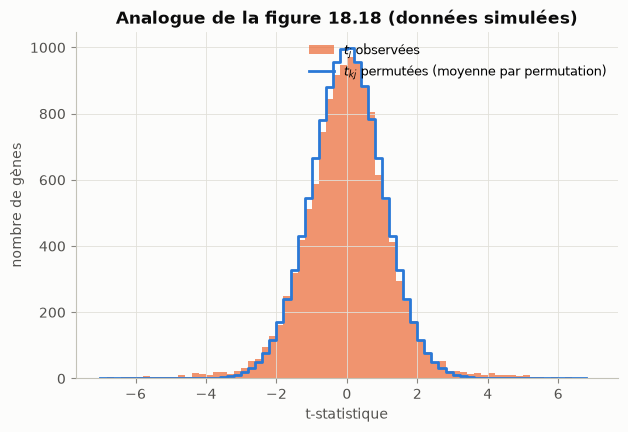

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(-7, 7, 71)
ax.hist(t_obs, bins=bins, color=ORANGE, alpha=0.7, label="$t_j$ observées")
h, _ = np.histogram(t_perm.ravel(), bins=bins)
ax.step(bins[:-1], h / t_perm.shape[1], where="post", color=BLUE,
        label="$t_{kj}$ permutées (moyenne par permutation)")
ax.set_xlabel("t-statistique")
ax.set_ylabel("nombre de gènes")
ax.set_title("Analogue de la figure 18.18 (données simulées)")
ax.legend()
plt.show()

Comme dans la figure 18.18 du livre, la distribution observée a des queues plus
épaisses que la distribution de permutation (qui représente l'hypothèse nulle).

### (a) FDR plug-in pour une grille de seuils

Pour chaque seuil $C$ on calcule $R_{\text{obs}}(C)$, $\widehat{E(V)}(C)$ et
$\widehat{\text{FDR}}(C)$ (algorithme 18.3, fonction `plugin_fdr`). Grâce à la
simulation, on affiche aussi le **vrai** taux de fausses découvertes parmi les gènes
rejetés, $V/R$.

In [13]:
C_grid = np.array([2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])
fdr_a, R_a, EV_a = g18.plugin_fdr(t_obs, t_perm, C_grid)
print("   C   R_obs   E(V)_hat   FDR_hat   vrai V/R")
for C, r, ev, f in zip(C_grid, R_a, EV_a, fdr_a):
    rej = np.abs(t_obs) >= C
    print("%4.1f  %6d  %9.1f   %7.3f   %7.3f" % (C, r, ev, f, np.mean(~non_nul[rej])))

   C   R_obs   E(V)_hat   FDR_hat   vrai V/R
 2.0    1052      635.7     0.604     0.578
 2.5     576      193.5     0.336     0.339
 3.0     368       50.4     0.137     0.133
 3.5     270       11.5     0.042     0.063
 4.0     194        2.3     0.012     0.015
 4.5     129        0.4     0.003     0.008
 5.0      89        0.1     0.001     0.011


Le FDR estimé décroît quand le seuil augmente et suit bien le vrai rapport $V/R$. Les
écarts restants sont en partie aléatoires (pour les grands seuils, $R$ et surtout $V$
sont petits, donc $V/R$ est très variable d'un jeu de données à l'autre). En moyenne,
l'estimateur **surestime** légèrement le FDR, car $\widehat{E(V)}$ estime en fait
$(M/M_0)E(V)$ (les permutations traitent les $M$ gènes comme nuls). La question (c)
corrige ce biais.

### (b) Procédure BH pour plusieurs niveaux $\alpha$

On calcule les p-valeurs mutualisées (18.41) et on applique BH pour plusieurs
$\alpha$ ; on compare au plus petit seuil observé dont le FDR plug-in est sous $\alpha$
(exercice 18.17).

In [14]:
p_obs = g18.pooled_pvalues(t_obs, t_perm)
t_desc = np.sort(np.abs(t_obs))[::-1]
fdr_all, _, _ = g18.plugin_fdr(t_obs, t_perm, t_desc)   # FDR plug-in à chaque |T|_(l)
print(" alpha   L (BH)   seuil |T|_(L)   FDR_hat au seuil   rejets plug-in   identiques")
for a in [0.01, 0.05, 0.10, 0.15, 0.20, 0.30]:
    L, rej_bh = g18.benjamini_hochberg(p_obs, a)
    ok = np.nonzero(fdr_all < a)[0]
    rej_pi = np.abs(t_obs) >= t_desc[ok[-1]] if ok.size else np.zeros(M, bool)
    print(" %.2f   %6d   %13.3f   %16.3f   %14d   %s"
          % (a, L, t_desc[L - 1], fdr_all[L - 1], rej_pi.sum(), np.array_equal(rej_bh, rej_pi)))

 alpha   L (BH)   seuil |T|_(L)   FDR_hat au seuil   rejets plug-in   identiques
 0.01      185           4.073              0.010              185   True
 0.05      277           3.438              0.050              277   True
 0.10      336           3.143              0.099              336   True
 0.15      381           2.965              0.146              381   True
 0.20      418           2.820              0.200              418   True
 0.30      544           2.569              0.298              544   True


Pour chaque $\alpha$ : BH rejette les $L$ gènes de plus grandes $|t_j|$, le FDR plug-in
au seuil $|T|_{(L)}$ est juste en dessous de $\alpha$, et la règle plug-in rejette
exactement le même ensemble. La figure suivante est l'analogue de la figure 18.19 du
livre.

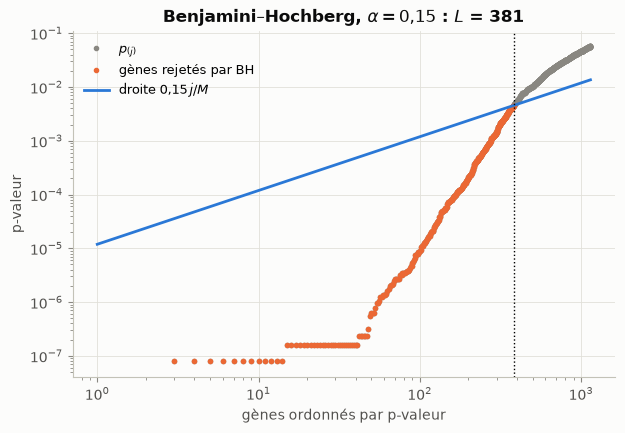

In [15]:
L15, rej15 = g18.benjamini_hochberg(p_obs, 0.15)
ps_sorted = np.sort(p_obs)
jj = np.arange(1, M + 1)
nmax = 3 * L15
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(jj[:nmax], ps_sorted[:nmax], "o", ms=3, color=GRAY, label="$p_{(j)}$")
ax.loglog(jj[:L15], ps_sorted[:L15], "o", ms=3, color=ORANGE, label="gènes rejetés par BH")
ax.loglog(jj[:nmax], 0.15 * jj[:nmax] / M, color=BLUE, label=r"droite $0{,}15\,j/M$")
ax.axvline(L15, color="k", lw=1, ls=":")
ax.set_xlabel("gènes ordonnés par p-valeur")
ax.set_ylabel("p-valeur")
ax.set_title(r"Benjamini–Hochberg, $\alpha = 0{,}15$ : $L$ = %d" % L15)
ax.legend()
plt.show()

Remarque sur la granularité : avec $MK \approx 1{,}3\times 10^7$ valeurs permutées, la
plus petite p-valeur non nulle est $\approx 8\times10^{-8}$ ; les gènes plus extrêmes que
toutes les valeurs permutées ont $p_j = 0$ (ils n'apparaissent pas sur l'échelle
logarithmique, mais sont bien rejetés).

### (c) Correction par $\hat\pi_0$

On calcule les quartiles des t-statistiques permutées, la proportion de t observées
entre ces quartiles, et $\hat\pi_0$ (fonction `pi0_quartile_estimate`).

In [16]:
q25, q75 = np.quantile(t_perm.ravel(), [0.25, 0.75])
pi0_hat = g18.pi0_quartile_estimate(t_obs, t_perm)
print("quartiles nuls : (%.3f, %.3f)" % (q25, q75))
print("pi0 estimé = %.4f   vrai pi0 = %.4f" % (pi0_hat, 1 - M1 / M))

quartiles nuls : (-0.678, 0.679)
pi0 estimé = 0.9711   vrai pi0 = 0.9604


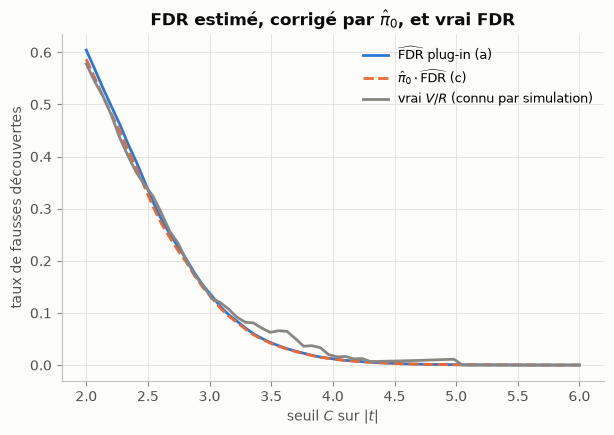

In [17]:
C_fine = np.linspace(2.0, 6.0, 60)
fdr_f, R_f, _ = g18.plugin_fdr(t_obs, t_perm, C_fine)
vrai = np.array([np.mean(~non_nul[np.abs(t_obs) >= C]) if np.any(np.abs(t_obs) >= C)
                 else np.nan for C in C_fine])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(C_fine, fdr_f, color=BLUE, label=r"$\widehat{\mathrm{FDR}}$ plug-in (a)")
ax.plot(C_fine, pi0_hat * fdr_f, color=ORANGE, ls="--",
        label=r"$\hat\pi_0 \cdot \widehat{\mathrm{FDR}}$ (c)")
ax.plot(C_fine, vrai, color=GRAY, label="vrai $V/R$ (connu par simulation)")
ax.set_xlabel("seuil $C$ sur $|t|$")
ax.set_ylabel("taux de fausses découvertes")
ax.set_title("FDR estimé, corrigé par $\\hat\\pi_0$, et vrai FDR")
ax.legend()
plt.show()

Ici $\hat\pi_0$ est proche de $1$ (car $\pi_0 \approx 0{,}96$) et la correction est
modeste : les deux courbes diffèrent de quelques pour cent. La correction devient
importante quand une part notable des gènes est différentielle. Vérifions-le en
refaisant le calcul avec $M_1 = 3000$ gènes différentiels ($\pi_0 \approx 0{,}76$).

In [18]:
non_nul2 = np.zeros(M, bool)
non_nul2[rng.choice(M, 3000, replace=False)] = True
Xm2 = rng.randn(M, N1 + N2) * sd[:, None]
eff2 = rng.choice([-1, 1], 3000) * rng.uniform(0.6, 1.6, 3000)
Xm2[np.ix_(non_nul2, sensible)] += (eff2 * sd[non_nul2])[:, None]
t2 = g18.two_sample_t(Xm2, sensible)
tp2 = g18.permutation_t(Xm2, sensible, 200, rng)
pi0_2 = g18.pi0_quartile_estimate(t2, tp2)
f2, _, _ = g18.plugin_fdr(t2, tp2, C_fine)
vrai2 = np.array([np.mean(~non_nul2[np.abs(t2) >= C]) if np.any(np.abs(t2) >= C)
                  else np.nan for C in C_fine])
print("pi0 estimé = %.3f   vrai pi0 = %.3f" % (pi0_2, 1 - 3000 / M))

pi0 estimé = 0.772   vrai pi0 = 0.762


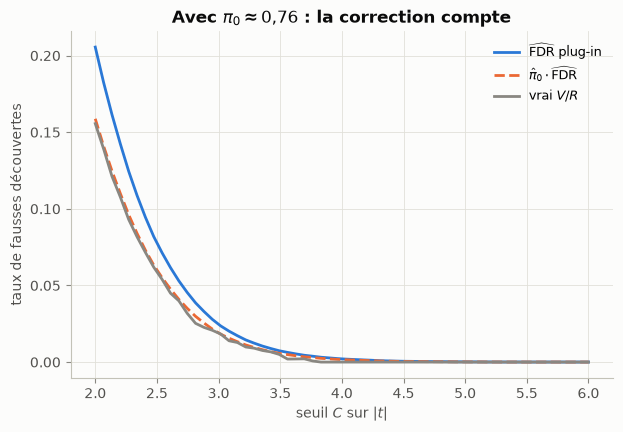

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(C_fine, f2, color=BLUE, label=r"$\widehat{\mathrm{FDR}}$ plug-in")
ax.plot(C_fine, pi0_2 * f2, color=ORANGE, ls="--", label=r"$\hat\pi_0 \cdot \widehat{\mathrm{FDR}}$")
ax.plot(C_fine, vrai2, color=GRAY, label="vrai $V/R$")
ax.set_xlabel("seuil $C$ sur $|t|$")
ax.set_ylabel("taux de fausses découvertes")
ax.set_title(r"Avec $\pi_0 \approx 0{,}76$ : la correction compte")
ax.legend()
plt.show()

Le FDR plug-in brut est nettement trop pessimiste ; multiplié par $\hat\pi_0$ il se
rapproche du vrai $V/R$, tout en restant un peu conservateur ($\hat\pi_0$ légèrement
au-dessus de $\pi_0$, voir (d)).

### (d) Pourquoi cet estimateur de $\pi_0$ ?

Utilisons le modèle de mélange (18.52) : $t_j \sim \pi_0F_0 + \pi_1F_1$.

1. La distribution de permutation approche $F_0$ ; par définition des quartiles,
   $\Pr_{F_0}\big(t \in (q_{.25}, q_{.75})\big) \approx 0{,}5$.
2. Les gènes réellement différentiels ont des statistiques **excentrées** : sous $F_1$,
   $t$ tombe rarement au centre de la distribution nulle, de sorte que
   $\Pr_{F_1}\big(t \in (q_{.25}, q_{.75})\big) = \varepsilon$ est petit.
3. Par la formule des probabilités totales,
   $$\Pr\big(t_j \in (q_{.25}, q_{.75})\big) = 0{,}5\,\pi_0 + \varepsilon\,\pi_1 .$$
   Par la loi des grands nombres, la proportion observée
   $\#\{t_j \in (q_{.25}, q_{.75})\}/M$ est proche de cette probabilité. En divisant par
   $0{,}5$ :
   $$\hat\pi_0 \approx \pi_0 + 2\varepsilon\,\pi_1 \ \ge\ \pi_0 .$$

L'estimateur est donc **légèrement biaisé vers le haut** (d'autant moins que les
non-nuls sont rarement au centre), ce qui rend le FDR corrigé encore conservateur. La
troncature à $1$ évite une valeur absurde. Enfin, multiplier par $\hat\pi_0$ se justifie
car $\widehat{E(V)}$ compte $M$ gènes nuls au lieu de $M_0 = \pi_0M$ : $\hat\pi_0\cdot
\widehat{\text{FDR}} = (\hat M_0/M)\,\widehat{\text{FDR}}$ (section 18.7.1).

> **À retenir.** Le FDR plug-in et BH donnent les mêmes listes de gènes ; tous deux
> supposent implicitement $M_0 = M$ et sont conservateurs. Le centre de la distribution
> observée est peuplé presque uniquement de nuls, ce qui permet d'estimer $\pi_0$ et de
> corriger le FDR par le facteur $\hat\pi_0$.

## Exercice 18.20 : Démonstration du résultat (18.53)

**Énoncé (reformulé).** Écrire

$$
\text{pFDR} = E\Big(\frac VR \,\Big|\, R > 0\Big)
 = \sum_{k=1}^M E\Big(\frac VR \,\Big|\, R = k\Big)\Pr(R = k \mid R > 0)
\qquad\text{(éq. (18.60)–(18.61))},
$$

et utiliser le fait que, sachant $R = k$, $V$ suit une loi binomiale de paramètres
$k$ et $\Pr(H = 0 \mid T \in \Gamma)$ pour terminer la preuve de
$\text{pFDR}(\Gamma) = \Pr(Z_j = 0 \mid t_j \in \Gamma)$.

### Étape 1 : décomposition (18.61)

L'événement $\{R > 0\}$ est la réunion disjointe des $\{R = k\}$, $k = 1, \dots, M$.
La formule de l'espérance totale (conditionnement par la valeur de $R$) donne

$$
E\Big(\frac VR \,\Big|\, R > 0\Big) = \sum_{k=1}^M E\Big(\frac VR \,\Big|\, R = k\Big)\Pr(R = k \mid R > 0)
$$

(seuls les $k$ tels que $\Pr(R = k) > 0$ interviennent). Sur $\{R = k\}$, $V/R = V/k$,
donc $E(V/R \mid R = k) = E(V \mid R = k)/k$.

### Étape 2 : loi de $V$ sachant $R = k$

Notons $q = \Pr(Z_j = 0 \mid t_j \in \Gamma)$ (identique pour tout $j$, car les couples
$(t_j, Z_j)$ ont même loi). Fixons un ensemble $S \subset \{1, \dots, M\}$ de cardinal
$k$ et conditionnons par l'événement
$E_S = \{t_j \in \Gamma \text{ pour } j \in S,\ t_j \notin \Gamma \text{ pour } j \notin S\}$
(« les tests rejetés sont exactement ceux de $S$ »).

Comme les couples $(t_j, Z_j)$ sont **indépendants**, pour tout choix de
$z_j \in \{0, 1\}$, $j \in S$ :

$$
\Pr\big(Z_j = z_j\ \forall j \in S \,\big|\, E_S\big)
 = \frac{\prod_{j \in S}\Pr(Z_j = z_j, t_j \in \Gamma)\prod_{j \notin S}\Pr(t_j \notin \Gamma)}
        {\prod_{j \in S}\Pr(t_j \in \Gamma)\prod_{j \notin S}\Pr(t_j \notin \Gamma)}
 = \prod_{j \in S}\Pr(Z_j = z_j \mid t_j \in \Gamma) .
$$

Sachant $E_S$, les $Z_j$, $j \in S$, sont donc indépendants, et chacun vaut $0$ avec
probabilité $q$. Or $V = \#\{j \in S : Z_j = 0\}$ est la somme de $k$ indicatrices
indépendantes de paramètre $q$ : $V \mid E_S \sim \mathcal B(k, q)$. Cette loi ne
dépend pas de $S$ ; comme $\{R = k\}$ est la réunion disjointe des $E_S$ avec $|S| = k$,
on obtient en moyennant

$$
V \mid R = k \ \sim\ \mathcal B(k, q), \qquad E(V \mid R = k) = kq .
$$

### Étape 3 : conclusion

En reportant dans l'étape 1 : $E(V/R \mid R = k) = kq/k = q$ pour tout $k \ge 1$, d'où

$$
\text{pFDR} = \sum_{k=1}^M q\,\Pr(R = k \mid R > 0) = q\sum_{k=1}^M \Pr(R = k \mid R > 0) = q ,
$$

car les probabilités conditionnelles $\Pr(R = k \mid R > 0)$, $k = 1, \dots, M$, somment
à $1$. Ainsi $\text{pFDR}(\Gamma) = \Pr(Z_j = 0 \mid t_j \in \Gamma)$. $\blacksquare$

> **Remarque.** Le résultat ne dépend pas de $M$ : c'est une propriété « par test » du
> modèle de mélange. Il repose de façon essentielle sur l'indépendance des couples
> $(t_j, Z_j)$ ; avec des tests dépendants, $V \mid R = k$ n'est plus binomiale.

### Vérification par simulation

On reprend le mélange de l'exercice 18.18 ($\pi_0 = 0{,}8$, $F_1 = \mathcal N(2{,}5, 1)$)
avec $M = 50$ tests et $\Gamma = \{|t| > 2\}$. On regarde la loi empirique de $V$ sachant
$R = k$ pour la valeur de $k$ la plus fréquente, et on la compare à $\mathcal B(k, q)$.

In [20]:
rng = np.random.RandomState(3)
pi0, mu1, M, c, n_rep = 0.8, 2.5, 50, 2.0, 100000
Zs = rng.rand(n_rep, M) > pi0
tt = rng.randn(n_rep, M) + mu1 * Zs
rej = np.abs(tt) > c
R = rej.sum(axis=1)
V = (rej & ~Zs).sum(axis=1)
a0 = 2 * stats.norm.sf(c)
pw = stats.norm.sf(c - mu1) + stats.norm.cdf(-c - mu1)
q = pi0 * a0 / (pi0 * a0 + (1 - pi0) * pw)
print("q = Pr(Z = 0 | t dans Gamma) = %.4f" % q)
print("pFDR simulé E(V/R | R > 0) = %.4f" % np.mean(V[R > 0] / R[R > 0]))

q = Pr(Z = 0 | t dans Gamma) = 0.2084
pFDR simulé E(V/R | R > 0) = 0.2084


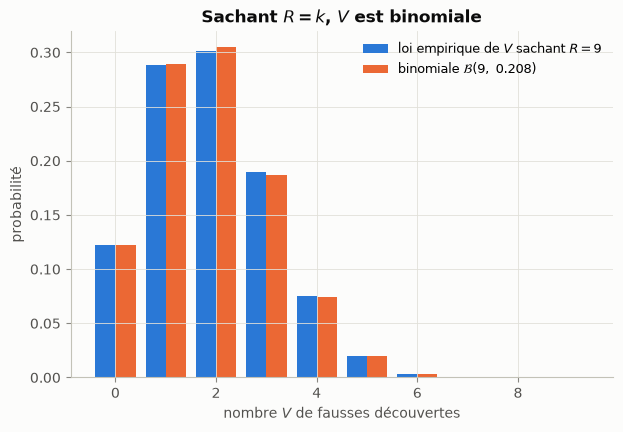

In [21]:
k = np.bincount(R).argmax()
vk = V[R == k]
fig, ax = plt.subplots(figsize=(7, 4.5))
vals = np.arange(k + 1)
ax.bar(vals - 0.2, np.bincount(vk, minlength=k + 1) / len(vk), width=0.4, color=BLUE,
       label="loi empirique de $V$ sachant $R = %d$" % k)
ax.bar(vals + 0.2, stats.binom.pmf(vals, k, q), width=0.4, color=ORANGE,
       label="binomiale $\\mathcal{B}(%d,\\ %.3f)$" % (k, q))
ax.set_xlabel("nombre $V$ de fausses découvertes")
ax.set_ylabel("probabilité")
ax.set_title("Sachant $R = k$, $V$ est binomiale")
ax.legend()
plt.show()

Et pour chaque valeur de $k$ assez fréquente, la moyenne de $V/k$ sachant $R = k$ est
bien constante, égale à $q$.

In [ ]:
ks = [kk for kk in range(1, M + 1) if np.sum(R == kk) > 500]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ks, [np.mean(V[R == kk]) / kk for kk in ks], "o", color=BLUE,
        label=r"moyenne empirique de $V/R$ sachant $R = k$")
ax.axhline(q, color=ORANGE, label=r"$q = \Pr(Z = 0 \mid t \in \Gamma)$")
ax.set_ylim(0, 2 * q)
ax.set_xlabel("$k$")
ax.set_ylabel(r"$E(V/R \mid R = k)$")
ax.set_title(r"$E(V/R \mid R = k)$ ne dépend pas de $k$")
ax.legend()
plt.show()

> **À retenir.** Sous le modèle de mélange à couples $(t_j, Z_j)$ i.i.d., parmi $k$
> rejets chacun est « nul » indépendamment avec probabilité $q = \Pr(Z = 0 \mid t \in \Gamma)$ :
> $V \mid R = k \sim \mathcal B(k, q)$, donc $E(V/R \mid R = k) = q$ pour tout $k$ et
> $\text{pFDR} = q$.